In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
from sklearn.decomposition import PCA

In [4]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"

df = pd.read_csv(url)

print(df.head())


   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa


In [5]:
print(df.shape)


(150, 5)


In [6]:
print(df.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB
None


In [7]:
print(df.isnull().sum())


sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


In [8]:
print(df.describe())

       sepal_length  sepal_width  petal_length  petal_width
count    150.000000   150.000000    150.000000   150.000000
mean       5.843333     3.057333      3.758000     1.199333
std        0.828066     0.435866      1.765298     0.762238
min        4.300000     2.000000      1.000000     0.100000
25%        5.100000     2.800000      1.600000     0.300000
50%        5.800000     3.000000      4.350000     1.300000
75%        6.400000     3.300000      5.100000     1.800000
max        7.900000     4.400000      6.900000     2.500000


species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


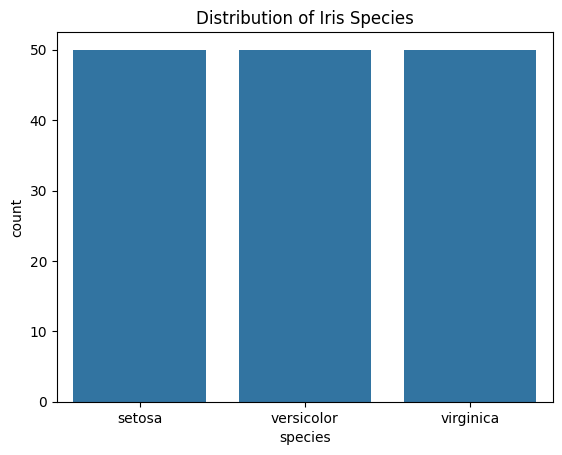

In [10]:
print(df['species'].value_counts())

sns.countplot(data=df, x='species')
plt.title("Distribution of Iris Species")
plt.show()

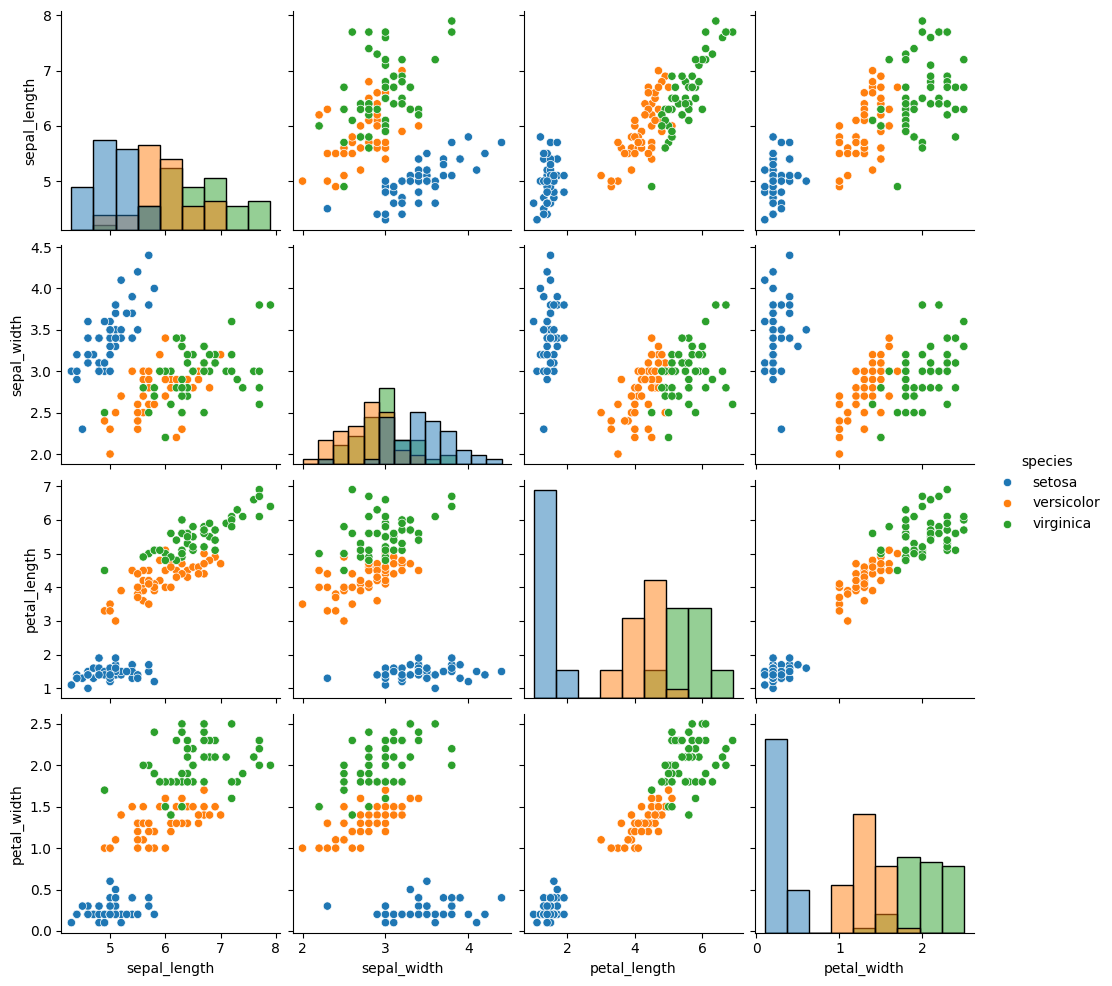

In [11]:
sns.pairplot(df, hue='species', diag_kind='hist')
plt.show()

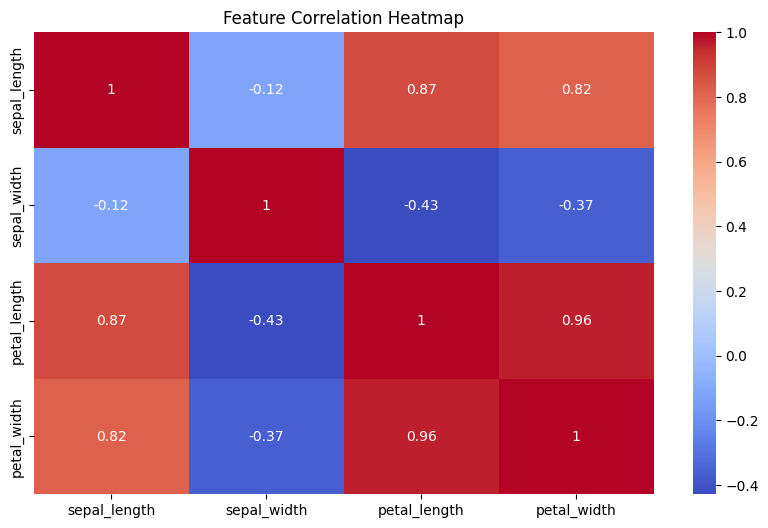

In [12]:
plt.figure(figsize=(10, 6))
sns.heatmap(df.drop(columns='species').corr(), annot=True, cmap='coolwarm')
plt.title("Feature Correlation Heatmap")
plt.show()

In [13]:
X = df.drop('species', axis=1)
y = df['species']

print("Features:")
print(X.head())

print("Target:")
print(y.head())

Features:
   sepal_length  sepal_width  petal_length  petal_width
0           5.1          3.5           1.4          0.2
1           4.9          3.0           1.4          0.2
2           4.7          3.2           1.3          0.2
3           4.6          3.1           1.5          0.2
4           5.0          3.6           1.4          0.2
Target:
0    setosa
1    setosa
2    setosa
3    setosa
4    setosa
Name: species, dtype: object


In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

Training Samples: 120
Testing Samples: 30


In [19]:
logistic_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000))
])

logistic_model.fit(X_train, y_train)

logistic_predictions = logistic_model.predict(X_test)

In [21]:
decision_tree_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', DecisionTreeClassifier(random_state=42))
])

decision_tree_model.fit(X_train, y_train)

tree_predictions = decision_tree_model.predict(X_test)

In [22]:
results = []

models = {
    "Logistic Regression": logistic_predictions,
    "Decision Tree": tree_predictions
}

for model_name, predictions in models.items():

    accuracy = accuracy_score(y_test, predictions)

    precision = precision_score(
        y_test, predictions, average='weighted'
    )

    recall = recall_score(
        y_test, predictions, average='weighted'
    )

    f1 = f1_score(
        y_test, predictions, average='weighted'
    )

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

results_df = pd.DataFrame(results)

print(results_df.round(4))

                 Model  Accuracy  Precision  Recall  F1-Score
0  Logistic Regression    0.9333     0.9333  0.9333    0.9333
1        Decision Tree    0.9333     0.9333  0.9333    0.9333


In [23]:
print("Logistic Regression Report")
print(classification_report(y_test, logistic_predictions))

print("Decision Tree Report")
print(classification_report(y_test, tree_predictions))

Logistic Regression Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

Decision Tree Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



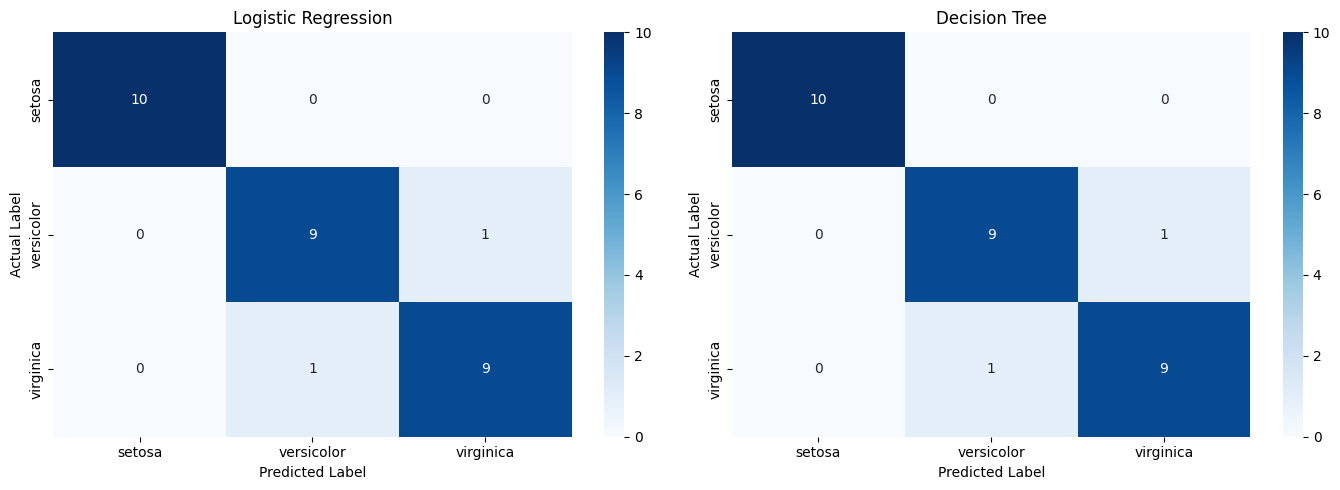

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

predictions_list = [
    (logistic_predictions, "Logistic Regression"),
    (tree_predictions, "Decision Tree")
]

for ax, (predictions, title) in zip(axes, predictions_list):

    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=np.unique(y),
        yticklabels=np.unique(y),
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

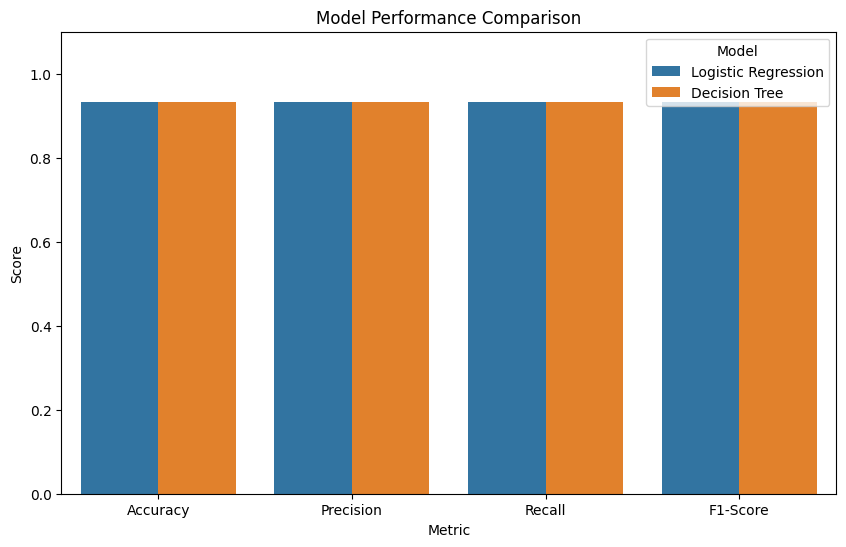

In [25]:
results_melted = results_df.melt(
    id_vars='Model',
    var_name='Metric',
    value_name='Score'
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_melted,
    x='Metric',
    y='Score',
    hue='Model'
)

plt.title("Model Performance Comparison")
plt.ylim(0, 1.1)
plt.show()

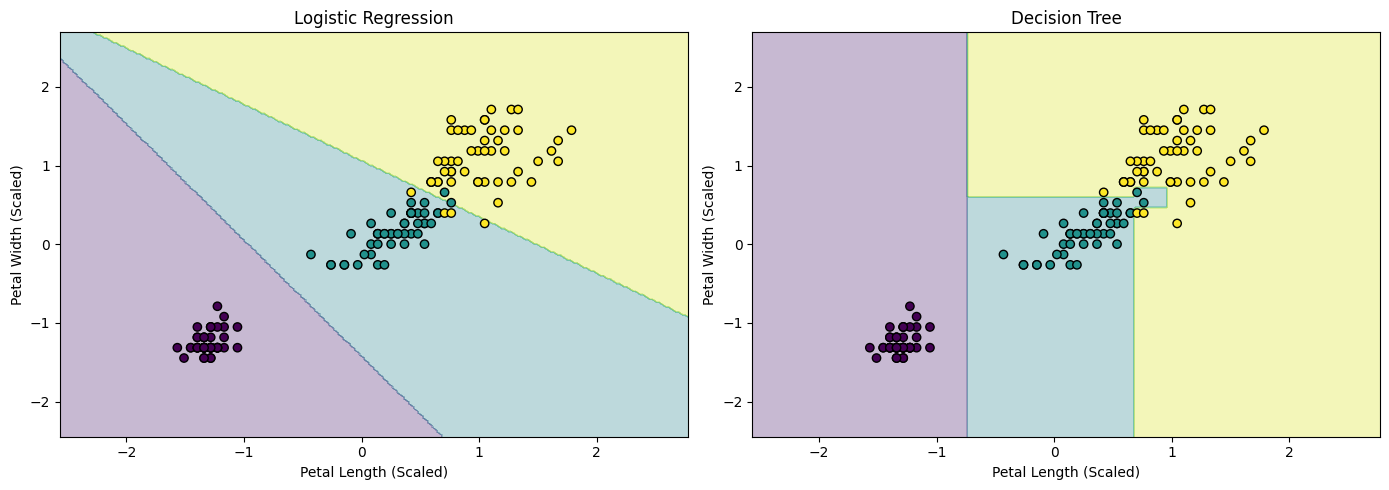

In [26]:
X_2d = df[['petal_length', 'petal_width']]
y_2d = df['species']

scaler_2d = StandardScaler()
X_2d_scaled = scaler_2d.fit_transform(X_2d)

logistic_2d = LogisticRegression(max_iter=1000)
tree_2d = DecisionTreeClassifier(random_state=42)

logistic_2d.fit(X_2d_scaled, y_2d)
tree_2d.fit(X_2d_scaled, y_2d)

x_min, x_max = X_2d_scaled[:, 0].min() - 1, X_2d_scaled[:, 0].max() + 1
y_min, y_max = X_2d_scaled[:, 1].min() - 1, X_2d_scaled[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.02),
    np.arange(y_min, y_max, 0.02)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, model, title in zip(
    axes,
    [logistic_2d, tree_2d],
    ["Logistic Regression", "Decision Tree"]
):

    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = pd.Categorical(Z, categories=np.unique(y_2d)).codes
    Z = Z.reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.3, cmap='viridis')

    ax.scatter(
        X_2d_scaled[:, 0],
        X_2d_scaled[:, 1],
        c=pd.Categorical(y_2d, categories=np.unique(y_2d)).codes,
        cmap='viridis',
        edgecolors='black'
    )

    ax.set_title(title)
    ax.set_xlabel("Petal Length (Scaled)")
    ax.set_ylabel("Petal Width (Scaled)")

plt.tight_layout()
plt.show()